# Assignment 3 M3 | Results Analysis

Five-class meme sentiment using image and corrected text. This notebook reuses the project's train and evaluate commands. It records the exact runs behind the tables.

1. Select the Assignment 3 `.venv` kernel. With all switches off, run the notebook to review existing evidence.
2. To train a new set, enable `RUN_TRAINING` and leave `RUN_TEST` off. Each completed run is recorded and skipped when resuming the same group.
3. Review **validation** first. After locking the five run IDs, turn training off, enable `USE_NOTEBOOK_RUNS` and `RUN_TEST`, then rerun. Turn `RUN_TEST` off again before saving or sharing.
4. Run the analysis cells and save the notebook with outputs. Select and review real memes before using them in the report.

In [19]:
from pathlib import Path
import csv
import json
import os
import subprocess
import sys
from textwrap import fill

from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from PIL import Image

HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / "config/base.yaml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the assignment3 workspace.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.reproducibility import data_fingerprint

DEVICE = "cuda"
SEED = 42
RUN_GROUP = "m3-rerun-seed42"
RUN_TRAINING = False
USE_NOTEBOOK_RUNS = True
RUN_TEST = True

if RUN_TRAINING and RUN_TEST:
    raise ValueError("Run training first, review validation, then enable test evaluation.")

MODELS = ("image_only", "text_only", "concat", "gated", "fixed_average")
LABELS = ("very_negative", "negative", "neutral", "positive", "very_positive")
EXISTING_IDS = {
    "image_only": "20261123-151823-614551-seed42",
    "text_only": "20261123-152755-078812-seed42",
    "concat": "20261123-153738-157379-seed42",
    "gated": "20261126-153713-308911-seed42",
    "fixed_average": "20261126-154638-678760-seed42",
}
RUNS_ROOT = ROOT / "results/runs"
MANIFEST = RUNS_ROOT / f"notebook-{RUN_GROUP}.json"

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def read_csv(path):
    with path.open(encoding="utf-8", newline="") as stream:
        return list(csv.DictReader(stream))

def table(headers, rows):
    def row(values):
        return "| " + " | ".join(str(v).replace("|", r"\|").replace("\n", " ") for v in values) + " |"
    display(Markdown("\n".join([row(headers), row(["---"] * len(headers)), *(row(r) for r in rows)])))

def cli(module, *args):
    command = [sys.executable, "-u", "-m", module, *map(str, args)]
    run_id = None
    with subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE,
                          stderr=subprocess.STDOUT, encoding="utf-8", errors="replace",
                          env={**os.environ, "PYTHONUTF8": "1"}) as proc:
        try:
            for line in proc.stdout:
                print(line, end="", flush=True)
                if line.startswith("Run id:"):
                    run_id = line.partition(":")[2].strip()
        finally:
            if sys.exc_info()[0] is not None and proc.poll() is None:
                proc.terminate()
        if proc.wait():
            raise subprocess.CalledProcessError(proc.returncode, command)
    return run_id

print(f"Assignment root: {ROOT}\nKernel: {sys.executable}")

Assignment root: C:\DeepLearning\CO3133-261-GroupXX\assignment3
Kernel: c:\DeepLearning\CO3133-261-GroupXX\assignment3\.venv\Scripts\python.exe


## 1. Train the five core models (optional)

Keep the original configs, seed and splits. The notebook stores the run ID and checkpoint path after each successful model in an ignored JSON file. Reuse the same group name to resume, or change it when intentionally starting a different full rerun.

In [11]:
def run_path(model, run_id):
    return RUNS_ROOT / model / run_id

def load_run(folder, model, require_checkpoint=False):
    config = read_json(folder / "config.json")
    metadata = read_json(folder / "run_metadata.json")
    training = read_json(folder / "training.json")
    if (training["model"] != model or metadata["run_id"] != folder.name
            or training["seed"] != SEED or training["debug_run"]):
        raise ValueError(f"Unexpected model, seed, or debug run: {folder}")
    expected_labels = {label: idx for idx, label in enumerate(LABELS)}
    if config["labels"] != expected_labels or metadata["labels"] != expected_labels:
        raise ValueError(f"Unexpected label mapping: {folder}")
    current = data_fingerprint(config, ROOT)
    if any(current.get(key) != metadata["data"].get(key)
           for key in ("train_manifest", "val_manifest", "test_manifest", "vocabulary", "text_tokenizer")):
        raise ValueError(f"Manifest or tokenizer changed since training: {folder}")
    if not training["reload_check"]["passed"]:
        raise ValueError(f"Checkpoint did not reproduce validation Macro-F1: {folder}")
    checkpoint = ROOT / metadata["checkpoint_path"]
    if require_checkpoint and not checkpoint.is_file():
        raise FileNotFoundError(checkpoint)
    return {"folder": folder, "config": config, "metadata": metadata,
            "training": training, "checkpoint": checkpoint}

if RUN_TRAINING:
    receipt = read_json(MANIFEST) if MANIFEST.exists() else {}
    for model in MODELS:
        if model in receipt:
            load_run(run_path(model, receipt[model]["run_id"]), model, require_checkpoint=True)
            print(f"Reusing completed run: {model} {receipt[model]['run_id']}")
            continue
        run_id = cli("experiments.train", "--config", f"config/{model}.yaml",
                     "--seed", SEED, "--device", DEVICE, "--run-name", RUN_GROUP)
        if not run_id:
            raise RuntimeError(f"Training did not report the run ID for {model}.")
        run = load_run(run_path(model, run_id), model, require_checkpoint=True)
        receipt[model] = {"run_id": run_id, "checkpoint": run["checkpoint"].relative_to(ROOT).as_posix()}
        temporary = MANIFEST.with_suffix(".tmp")
        temporary.write_text(json.dumps(receipt, indent=2) + "\n", encoding="utf-8")
        temporary.replace(MANIFEST)
    print(f"Run record: {MANIFEST}")
else:
    print("Training skipped. Enable RUN_TRAINING in Settings to start or resume.")

Run 20261128-134442-171613-seed42-m3-rerun-seed42 | model image_only | device cuda | train 4819 / val 1034 | trainable params 2,565
Epoch 01/20 | train loss 1.3871 | val loss 1.3032 | val accuracy 44.10% | val Macro-F1 0.1249 | new best
Epoch 02/20 | train loss 1.3151 | val loss 1.3115 | val accuracy 41.01% | val Macro-F1 0.1779 | new best
Epoch 03/20 | train loss 1.2972 | val loss 1.3066 | val accuracy 39.17% | val Macro-F1 0.1746
Epoch 04/20 | train loss 1.2916 | val loss 1.3081 | val accuracy 44.49% | val Macro-F1 0.1330
Epoch 05/20 | train loss 1.2841 | val loss 1.3215 | val accuracy 43.91% | val Macro-F1 0.1383
Epoch 06/20 | train loss 1.2863 | val loss 1.3027 | val accuracy 44.20% | val Macro-F1 0.1334
Epoch 07/20 | train loss 1.2682 | val loss 1.3110 | val accuracy 44.20% | val Macro-F1 0.1302
Best epoch 2/7 | val macro-F1 0.1779 | val accuracy 0.4101 | 343s | peak VRAM 1298 MiB
Run directory: C:\DeepLearning\CO3133-261-GroupXX\assignment3\results\runs\image_only\20261128-134442

## 2. Select the five runs

The table records the checkpoint selected by validation Macro-F1 for each model. Review the validation results before enabling held-out test evaluation.

In [12]:
if RUN_TRAINING or USE_NOTEBOOK_RUNS:
    if not MANIFEST.exists():
        raise FileNotFoundError(f"No completed notebook runs recorded at {MANIFEST}")
    run_ids = {model: entry["run_id"] for model, entry in read_json(MANIFEST).items()}
else:
    run_ids = EXISTING_IDS.copy()

runs = {}
for model in MODELS:
    run_id = run_ids.get(model)
    folder = run_path(model, run_id) if run_id else None
    if folder is None or not (folder / "training.json").is_file():
        print(f"Missing completed run: {model} ({run_id or 'no run ID'})")
        continue
    runs[model] = load_run(folder, model, require_checkpoint=RUN_TEST)

table(("Model", "Run ID", "Best epoch", "Checkpoint"), (
    (m, run_ids[m], r["training"]["best_epoch"], r["metadata"]["checkpoint_path"])
    for m, r in runs.items()
))


| Model | Run ID | Best epoch | Checkpoint |
| --- | --- | --- | --- |
| image_only | 20261128-134442-171613-seed42-m3-rerun-seed42 | 2 | checkpoints/image_only/20261128-134442-171613-seed42-m3-rerun-seed42/best_model.pt |
| text_only | 20261128-135035-970092-seed42-m3-rerun-seed42 | 6 | checkpoints/text_only/20261128-135035-970092-seed42-m3-rerun-seed42/best_model.pt |
| concat | 20261128-135944-866053-seed42-m3-rerun-seed42 | 11 | checkpoints/concat/20261128-135944-866053-seed42-m3-rerun-seed42/best_model.pt |
| gated | 20261128-141256-822819-seed42-m3-rerun-seed42 | 6 | checkpoints/gated/20261128-141256-822819-seed42-m3-rerun-seed42/best_model.pt |
| fixed_average | 20261128-142209-090740-seed42-m3-rerun-seed42 | 7 | checkpoints/fixed_average/20261128-142209-090740-seed42-m3-rerun-seed42/best_model.pt |

### 2.1 Run held-out test for each checkpoint

Set RUN_TRAINING to False, USE_NOTEBOOK_RUNS to True, and RUN_TEST to True in Settings. Run Settings and the selection cell, then run this cell before the metrics table. This evaluates each selected checkpoint on the held-out test manifest. Existing test artifacts for the selected runs are reused.

In [20]:
if not RUN_TEST:
    print("Test skipped. Enable RUN_TEST in Settings to evaluate the selected checkpoints.")
else:
    missing = [model for model in MODELS if model not in runs]
    if missing:
        raise RuntimeError("Complete all five runs before test: " + ", ".join(missing))

    for index, model in enumerate(MODELS, start=1):
        folder = runs[model]["folder"]
        print(f"[{index}/{len(MODELS)}] {model} | {folder.name}", flush=True)
        artifacts = (folder / "evaluation_test.json", folder / "predictions_test.csv")
        if all(path.is_file() for path in artifacts):
            print("  Reusing saved test results.")
            continue
        cli("experiments.evaluate", "--run", folder, "--split", "test", "--device", DEVICE)
        if not all(path.is_file() for path in artifacts):
            raise RuntimeError(f"Expected test artifacts were not saved for {model}.")

    print("All five test results are ready. Run the metrics cell below to display the table.")

[1/5] image_only | 20261128-134442-171613-seed42-m3-rerun-seed42
NOTE: test split — use only for configurations already locked on validation.
image_only | test | n=1034 | accuracy 0.3975 | macro-F1 0.1726
Saved: C:\DeepLearning\CO3133-261-GroupXX\assignment3\results\runs\image_only\20261128-134442-171613-seed42-m3-rerun-seed42\evaluation_test.json
[2/5] text_only | 20261128-135035-970092-seed42-m3-rerun-seed42
NOTE: test split — use only for configurations already locked on validation.
text_only | test | n=1034 | accuracy 0.3569 | macro-F1 0.1840
Saved: C:\DeepLearning\CO3133-261-GroupXX\assignment3\results\runs\text_only\20261128-135035-970092-seed42-m3-rerun-seed42\evaluation_test.json
[3/5] concat | 20261128-135944-866053-seed42-m3-rerun-seed42
NOTE: test split — use only for configurations already locked on validation.
concat | test | n=1034 | accuracy 0.3588 | macro-F1 0.2229
Saved: C:\DeepLearning\CO3133-261-GroupXX\assignment3\results\runs\concat\20261128-135944-866053-seed42-m3

## 3. Validation and held-out test results

Use the five-class Macro-F1 as the primary metric and accuracy as the secondary metric. Each row is one seed. Missing results are listed explicitly. The always-positive baseline uses the most common label in training.

In [21]:
def get_evaluation(run, split, expected_count):
    path = run["folder"] / f"evaluation_{split}.json"
    if not path.exists():
        return None
    e = read_json(path)
    if (e["split"] != split or e["debug_run"] or e["run_id"] != run["folder"].name
            or e["num_samples"] != expected_count or tuple(e["label_names"]) != LABELS
            or e["checkpoint_epoch"] != run["training"]["best_epoch"]):
        raise ValueError(f"Evaluation does not match the selected checkpoint and split: {path}")
    return e

manifests = {split: read_csv(ROOT / f"data/manifests/{split}.csv") for split in ("val", "test")}
evaluations = {}
for split, records in manifests.items():
    results = {m: e for m, r in runs.items()
               if (e := get_evaluation(r, split, len(records))) is not None}
    evaluations[split] = results
    positive = sum(int(row["label_id"]) == LABELS.index("positive") for row in records)
    n = len(records)
    display(Markdown(f"### {split.upper()} ({n:,} pairs)"))
    table(("Model", "Accuracy", "Macro-F1"), [
        ("always positive", f"{positive/n:.2%}", f"{2*positive/(positive+n)/len(LABELS):.4f}"),
        *((m, f"{results[m]['accuracy']:.2%}", f"{results[m]['macro_f1']:.4f}")
          if m in results else (m, "pending", "pending") for m in MODELS),
    ])
    if {"gated", "fixed_average"} <= results.keys():
        gate, fixed = results["gated"], results["fixed_average"]
        display(Markdown(f"**Ablation (learned gate minus fixed average):** "
                         f"Macro-F1 {gate['macro_f1']-fixed['macro_f1']:+.4f}; "
                         f"accuracy {(gate['accuracy']-fixed['accuracy'])*100:+.2f} percentage points."))
    else:
        print("Ablation delta pending for this split.")

### VAL (1,034 pairs)

| Model | Accuracy | Macro-F1 |
| --- | --- | --- |
| always positive | 44.68% | 0.1235 |
| image_only | 41.01% | 0.1779 |
| text_only | 35.98% | 0.1995 |
| concat | 37.52% | 0.2294 |
| gated | 37.43% | 0.2239 |
| fixed_average | 35.40% | 0.2114 |

**Ablation (learned gate minus fixed average):** Macro-F1 +0.0126; accuracy +2.03 percentage points.

### TEST (1,034 pairs)

| Model | Accuracy | Macro-F1 |
| --- | --- | --- |
| always positive | 44.68% | 0.1235 |
| image_only | 39.75% | 0.1726 |
| text_only | 35.69% | 0.1840 |
| concat | 35.88% | 0.2229 |
| gated | 34.53% | 0.2006 |
| fixed_average | 35.88% | 0.1979 |

**Ablation (learned gate minus fixed average):** Macro-F1 +0.0027; accuracy -1.35 percentage points.

### VAL per-class metrics

| Model | Class | Precision | Recall | F1 | Support |
| --- | --- | --- | --- | --- | --- |
| image_only | very_negative | 0.000 | 0.000 | 0.000 | 22 |
| image_only | negative | 0.000 | 0.000 | 0.000 | 71 |
| image_only | neutral | 0.340 | 0.380 | 0.359 | 326 |
| image_only | positive | 0.448 | 0.649 | 0.531 | 462 |
| image_only | very_positive | 0.000 | 0.000 | 0.000 | 153 |
| text_only | very_negative | 0.167 | 0.045 | 0.071 | 22 |
| text_only | negative | 0.023 | 0.014 | 0.017 | 71 |
| text_only | neutral | 0.319 | 0.353 | 0.335 | 326 |
| text_only | positive | 0.454 | 0.530 | 0.489 | 462 |
| text_only | very_positive | 0.119 | 0.065 | 0.084 | 153 |
| concat | very_negative | 0.071 | 0.045 | 0.056 | 22 |
| concat | negative | 0.075 | 0.042 | 0.054 | 71 |
| concat | neutral | 0.320 | 0.331 | 0.325 | 326 |
| concat | positive | 0.466 | 0.537 | 0.499 | 462 |
| concat | very_positive | 0.255 | 0.183 | 0.213 | 153 |
| gated | very_negative | 0.000 | 0.000 | 0.000 | 22 |
| gated | negative | 0.108 | 0.056 | 0.074 | 71 |
| gated | neutral | 0.320 | 0.380 | 0.347 | 326 |
| gated | positive | 0.456 | 0.500 | 0.477 | 462 |
| gated | very_positive | 0.280 | 0.183 | 0.221 | 153 |
| fixed_average | very_negative | 0.091 | 0.045 | 0.061 | 22 |
| fixed_average | negative | 0.089 | 0.070 | 0.079 | 71 |
| fixed_average | neutral | 0.314 | 0.301 | 0.307 | 326 |
| fixed_average | positive | 0.445 | 0.532 | 0.485 | 462 |
| fixed_average | very_positive | 0.157 | 0.105 | 0.125 | 153 |

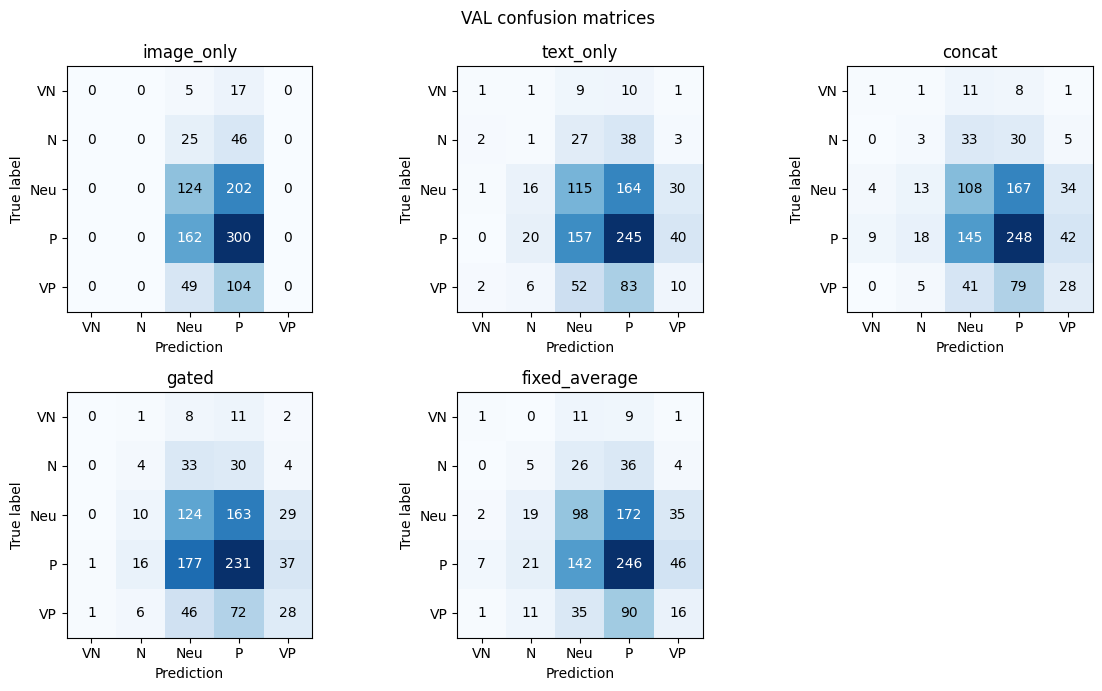

### TEST per-class metrics

| Model | Class | Precision | Recall | F1 | Support |
| --- | --- | --- | --- | --- | --- |
| image_only | very_negative | 0.000 | 0.000 | 0.000 | 23 |
| image_only | negative | 0.000 | 0.000 | 0.000 | 71 |
| image_only | neutral | 0.319 | 0.372 | 0.344 | 325 |
| image_only | positive | 0.443 | 0.628 | 0.519 | 462 |
| image_only | very_positive | 0.000 | 0.000 | 0.000 | 153 |
| text_only | very_negative | 0.000 | 0.000 | 0.000 | 23 |
| text_only | negative | 0.000 | 0.000 | 0.000 | 71 |
| text_only | neutral | 0.305 | 0.326 | 0.315 | 325 |
| text_only | positive | 0.441 | 0.539 | 0.485 | 462 |
| text_only | very_positive | 0.175 | 0.092 | 0.120 | 153 |
| concat | very_negative | 0.143 | 0.130 | 0.136 | 23 |
| concat | negative | 0.043 | 0.028 | 0.034 | 71 |
| concat | neutral | 0.332 | 0.342 | 0.337 | 325 |
| concat | positive | 0.462 | 0.517 | 0.488 | 462 |
| concat | very_positive | 0.138 | 0.105 | 0.119 | 153 |
| gated | very_negative | 0.200 | 0.043 | 0.071 | 23 |
| gated | negative | 0.019 | 0.014 | 0.016 | 71 |
| gated | neutral | 0.322 | 0.335 | 0.329 | 325 |
| gated | positive | 0.446 | 0.498 | 0.470 | 462 |
| gated | very_positive | 0.131 | 0.105 | 0.116 | 153 |
| fixed_average | very_negative | 0.000 | 0.000 | 0.000 | 23 |
| fixed_average | negative | 0.045 | 0.028 | 0.035 | 71 |
| fixed_average | neutral | 0.312 | 0.311 | 0.311 | 325 |
| fixed_average | positive | 0.453 | 0.537 | 0.492 | 462 |
| fixed_average | very_positive | 0.182 | 0.131 | 0.152 | 153 |

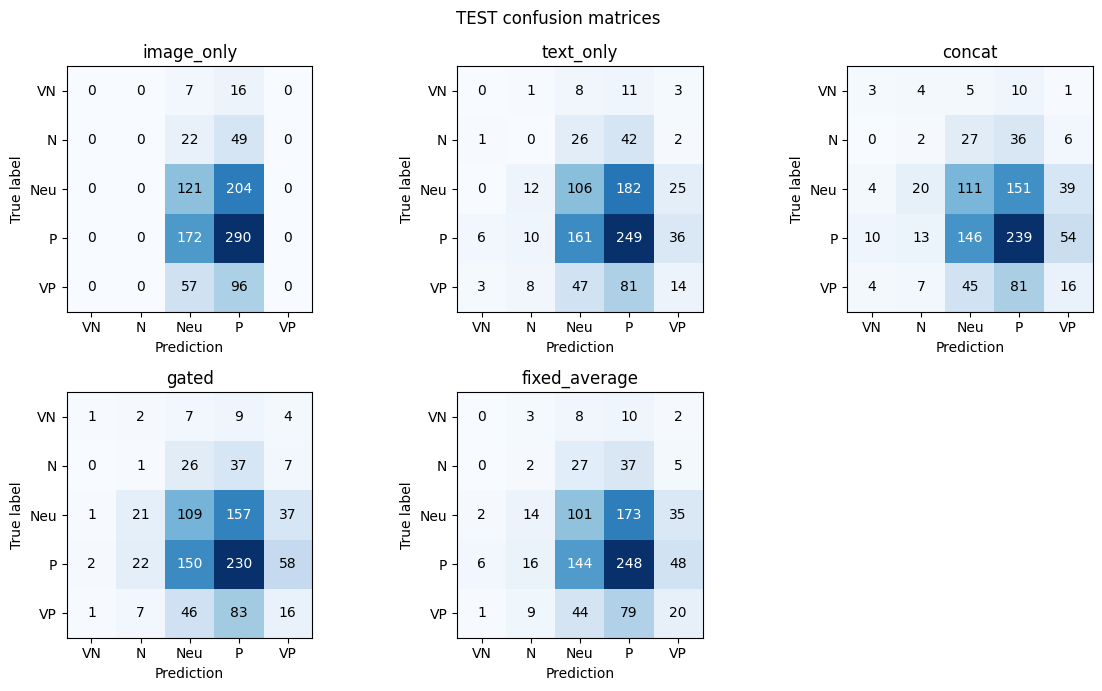

In [22]:
for split, results in evaluations.items():
    if not results:
        continue
    display(Markdown(f"### {split.upper()} per-class metrics"))
    table(("Model", "Class", "Precision", "Recall", "F1", "Support"), (
        (m, label, f"{x['precision']:.3f}", f"{x['recall']:.3f}", f"{x['f1']:.3f}", x["support"])
        for m, e in results.items()
        for label in LABELS
        for x in (e["per_class"][label],)
    ))
    cols = min(3, len(results))
    fig, axes = plt.subplots((len(results)+cols-1)//cols, cols, figsize=(4*cols, 3.5*((len(results)+cols-1)//cols)), squeeze=False)
    for ax, (m, e) in zip(axes.flat, results.items()):
        matrix = e["confusion_matrix"]
        ax.imshow(matrix, cmap="Blues")
        for i, row in enumerate(matrix):
            for j, count in enumerate(row):
                ax.text(j, i, count, ha="center", va="center",
                        color="white" if count > max(map(max, matrix))/2 else "black")
        ticks = range(len(LABELS))
        ax.set(xticks=ticks, yticks=ticks, xticklabels=("VN", "N", "Neu", "P", "VP"),
               yticklabels=("VN", "N", "Neu", "P", "VP"), xlabel="Prediction", ylabel="True label", title=m)
    for ax in list(axes.flat)[len(results):]:
        ax.set_visible(False)
    fig.suptitle(f"{split.upper()} confusion matrices")
    fig.tight_layout()
    plt.show()

## 4. Learning curves, training cost, and optional variants

Vertical lines mark checkpoints chosen by validation Macro-F1. Training loss and validation loss are directly comparable within the unweighted core models. Training-only weighting or smoothing changes the objective in the optional variants.

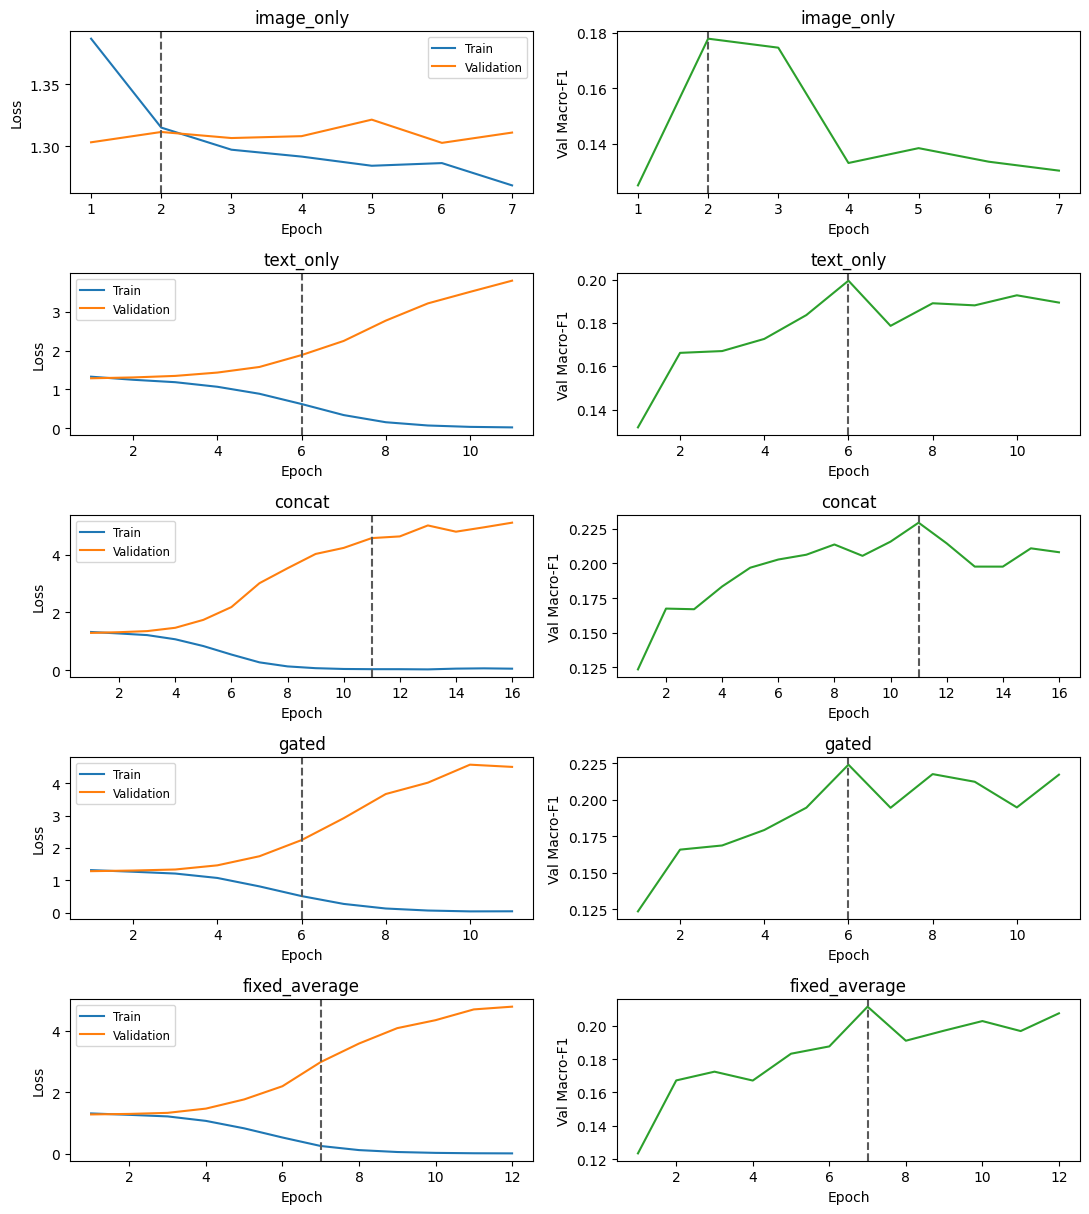

| Model | Trainable / total params | Device | Train seconds | Seconds / epoch | Peak GPU MiB |
| --- | --- | --- | --- | --- | --- |
| image_only | 2,565 / 11,179,077 | cuda | 343.3 | 49.0 | 1298.3 |
| text_only | 847,493 / 847,493 | cuda | 533.4 | 48.5 | 63.8 |
| concat | 1,045,893 / 12,222,405 | cuda | 780.9 | 48.8 | 1302.2 |
| gated | 1,175,941 / 12,352,453 | cuda | 542.2 | 49.3 | 1302.7 |
| fixed_average | 1,044,613 / 12,221,125 | cuda | 602.2 | 50.2 | 1302.2 |

Training time covers the training/validation loop. Inference latency is not measured by these artifacts.


In [23]:
if runs:
    fig, axes = plt.subplots(len(runs), 2, figsize=(11, 2.45*len(runs)), squeeze=False)
    for (loss_ax, f1_ax), (model, run) in zip(axes, runs.items()):
        t = run["training"]
        history = t["history"]
        epochs = [r["epoch"] for r in history]
        loss_ax.plot(epochs, [r["train_loss"] for r in history], label="Train")
        loss_ax.plot(epochs, [r["val_loss"] for r in history], label="Validation")
        loss_ax.legend(fontsize="small")
        f1_ax.plot(epochs, [r["val_macro_f1"] for r in history], color="tab:green")
        for ax, ylabel in ((loss_ax, "Loss"), (f1_ax, "Val Macro-F1")):
            ax.axvline(t["best_epoch"], color="0.35", linestyle="--")
            ax.set(xlabel="Epoch", ylabel=ylabel, title=model)
    fig.tight_layout()
    plt.show()

def metric(value, digits=1):
    return "unavailable" if value is None else f"{value:.{digits}f}"

table(("Model", "Trainable / total params", "Device", "Train seconds", "Seconds / epoch", "Peak GPU MiB"), (
    (m, f"{t['parameters']['trainable']:,} / {t['parameters']['total']:,}", c["device"],
     metric(c.get("training_seconds")), metric(c.get("seconds_per_epoch")),
     metric(c.get("peak_vram_allocated_mib")))
    for m, r in runs.items() for t in (r["training"],) for c in (t["compute"],)
))
print("Training time covers the training/validation loop. Inference latency is not measured by these artifacts.")

In [24]:
historical_reference = run_path("concat", EXISTING_IDS["concat"])
variant_folders = {
    "Original concat (historical)": historical_reference,
    "Class weighting": RUNS_ROOT / "weighted/concat/20261126-163419-859332-seed42",
    "Smaller GRU": RUNS_ROOT / "small_text/concat/20261126-165029-890927-seed42",
    "Label smoothing": RUNS_ROOT / "label_smoothing/concat/20261126-170819-345488-seed42",
    "ResNet-50 + DistilBERT": RUNS_ROOT / "resnet50_distilbert/concat/20261126-172622-350345-seed42",
    "Dropout 0.5": RUNS_ROOT / "dropout_05/concat/20261126-174006-845771-seed42",
}
variant_rows = []
for name, folder in variant_folders.items():
    if not (folder / "training.json").is_file():
        variant_rows.append((name, "unavailable locally", "-", "-", "-"))
        continue
    run = load_run(folder, "concat")
    e = get_evaluation(run, "val", len(manifests["val"]))
    if e is not None:
        t = run["training"]
        val_loss = next(row["val_loss"] for row in t["history"] if row["epoch"] == t["best_epoch"])
        variant_rows.append((name, folder.name, f"{e['accuracy']:.2%}", f"{e['macro_f1']:.4f}", f"{val_loss:.4f}"))
table(("Historical experiment", "Run ID", "Val accuracy", "Val Macro-F1", "Val loss at selection"), variant_rows)

| Historical experiment | Run ID | Val accuracy | Val Macro-F1 | Val loss at selection |
| --- | --- | --- | --- | --- |
| Original concat (historical) | 20261123-153738-157379-seed42 | 36.75% | 0.2298 | 3.4013 |
| Class weighting | 20261126-163419-859332-seed42 | 34.72% | 0.2139 | 3.1832 |
| Smaller GRU | 20261126-165029-890927-seed42 | 33.27% | 0.1931 | 2.3470 |
| Label smoothing | 20261126-170819-345488-seed42 | 35.69% | 0.2121 | 1.8856 |
| ResNet-50 + DistilBERT | 20261126-172622-350345-seed42 | 42.55% | 0.1756 | 1.2882 |
| Dropout 0.5 | 20261126-174006-845771-seed42 | 35.11% | 0.2118 | 3.5613 |

## 5. Inspect image/text interaction

Candidate examples are grouped by **prediction behavior**. Agreement or disagreement between models does not establish that the image and text agree or conflict in meaning. For the report, inspect each meme, explain the cue, and state why it is a support case, conflict case, or another kind of error. Use validation for exploratory review; change the split only for a locked final error analysis.

| Candidate group | Count |
| --- | --- |
| Both unimodal wrong, concat correct | 91 |
| Unimodal models disagree, concat wrong | 371 |
| Both unimodal correct, concat wrong | 73 |

**Both unimodal wrong, concat correct** | `image_1098.png` | target: `positive`

Corrected caption: DOWE SuperLotto AILLIONS 11930 751 MILLION MILLION ONE BILLION DOLLARS Dr Evil
takes over the Lottery I knew this would happen somewhere


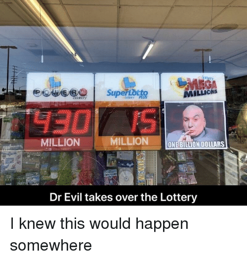

| Model | Prediction |
| --- | --- |
| image_only | neutral |
| text_only | very_positive |
| concat | positive |
| gated | positive |
| fixed_average | positive |

**Unimodal models disagree, concat wrong** | `image_1000.png` | target: `neutral`

Corrected caption: RT @BehindScenesPic: Martin Scorsese and Leonardo DiCaprio on the set of The
Departed https://t.co/RnXVYyHt44


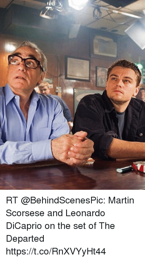

| Model | Prediction |
| --- | --- |
| image_only | positive |
| text_only | very_positive |
| concat | very_positive |
| gated | positive |
| fixed_average | neutral |

**Both unimodal correct, concat wrong** | `image_108.jpg` | target: `positive`

Corrected caption: MEXICANS LIKE ME THEY KEPT SAYING I WAS COOL. THEY KEPT SAYING I WAS A COOLO.
imgflip.com


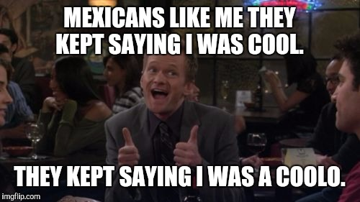

| Model | Prediction |
| --- | --- |
| image_only | positive |
| text_only | positive |
| concat | neutral |
| gated | positive |
| fixed_average | positive |

In [25]:
CASE_SPLIT = "val"
CASES_PER_GROUP = 1
CASE_MODELS = ("image_only", "text_only", "concat")

if not set(CASE_MODELS) <= evaluations[CASE_SPLIT].keys():
    print(f"Case review needs image-only, text-only and concat results on {CASE_SPLIT}.")
else:
    manifest = {r["image_name"]: r for r in manifests[CASE_SPLIT]}
    predictions = {}
    for model in evaluations[CASE_SPLIT]:
        rows = read_csv(runs[model]["folder"] / f"predictions_{CASE_SPLIT}.csv")
        by_id = {r["image_name"]: r for r in rows}
        if (len(rows) != len(by_id) or by_id.keys() != manifest.keys()
                or any(r["label_id"] != manifest[key]["label_id"] for key, r in by_id.items())):
            raise ValueError(f"Prediction rows do not align with {CASE_SPLIT}: {model}")
        predictions[model] = by_id

    buckets = {"Both unimodal wrong, concat correct": [],
               "Unimodal models disagree, concat wrong": [],
               "Both unimodal correct, concat wrong": []}
    for image_name in sorted(manifest):
        y = int(manifest[image_name]["label_id"])
        i, t, c = (int(predictions[m][image_name]["pred_id"]) for m in CASE_MODELS)
        if i != y and t != y and c == y:
            buckets["Both unimodal wrong, concat correct"].append(image_name)
        if i != t and c != y:
            buckets["Unimodal models disagree, concat wrong"].append(image_name)
        if i == t == y and c != y:
            buckets["Both unimodal correct, concat wrong"].append(image_name)

    table(("Candidate group", "Count"), ((k, len(v)) for k, v in buckets.items()))
    for category, names in buckets.items():
        for key in names[:CASES_PER_GROUP]:
            r = manifest[key]
            display(Markdown(f"**{category}** | `{key}` | target: `{LABELS[int(r['label_id'])]}`"))
            print("Corrected caption:", fill(r["text_corrected"], width=80))
            image_path = ROOT / r["image_path"]
            if image_path.is_file():
                with Image.open(image_path) as image:
                    preview = image.convert("RGBA").convert("RGB")
                    preview.thumbnail((360, 260))
                    display(preview)
            else:
                print("Raw image unavailable locally.")
            table(("Model", "Prediction"), ((m, by_id[key]["pred"]) for m, by_id in predictions.items()))

## 6. Handover to report, slides, and assignment page

- Record the selected run IDs, checkpoint paths, data hashes, and commit/dirty status from the run metadata.
- Keep validation and test tables separate. Compare learned gating to fixed averaging and document the single-seed limit.
- Add the reviewed image/text support and conflict examples and a compute analysis. Record inference latency separately if measured.
- Save the executed notebook after checking its outputs. Keep raw data, large checkpoints, and ignored run artifacts outside Git and share access or reproduction instructions.